### **Short Time Fourier Transform (STFT)**

___

In [1]:
%load_ext autoreload
%autoreload 2
import sys, os
import time
import numpy as np 
import matplotlib.pyplot as plt
import librosa 

sys.path.insert(0, os.path.abspath(".."))
from dsp.similarity import cosine_similarity
from dsp.signal_generator import make_time, create_sin
from dsp.spectral import frame_signal, stft
from IPython.display import Audio

ST1 (โค้ด + สังเกต) Spectral leakage และ Hann window
  - **ทำ:**
    - สร้าง notebook ใหม่ `notebooks/06_STFT.ipynb`
    - `sr = 1000` สร้าง `t` 1 วินาที → `N` ได้ 1000
    - `x1 = create_sin(1, 100, t)` และ `x2 = create_sin(1, 100.5, t)`
    - คำนวณ `mag` แบบ F3 (`np.abs(np.fft.fft(x)) * 2 / N`) ของทั้งสองตัว เก็บเฉพาะครึ่งแรก
    - print ค่าสูงสุดของ `mag` แต่ละตัว
    - นับจำนวน bin ที่ `mag > 0.01` ของแต่ละตัว → print
    - `w = np.hanning(N)` → ทำซ้ำกับ `x1 * w` และ `x2 * w` (print ค่าสูงสุด และจำนวน bin > 0.01)
    - พล็อต stem ช่วง 80–120 Hz ของ `x2` แบบไม่มี window กับมี window ด้วย `plt.subplots(2, 1)`
  - **เครื่องมือใหม่:**
    - `np.hanning(5)` → `[0, 0.5, 1, 0.5, 0]` หน้าต่างที่ค่อย ๆ ขึ้นจาก 0 แล้วลงกลับไป 0
    - นับจำนวนที่เข้าเงื่อนไข: `np.sum(np.array([0.5, 0.001, 0.2]) > 0.01)` → 2
  - **ตอบ:**
    1. ค่าสูงสุดของ `mag` ที่ 100 Hz กับ 100.5 Hz (ไม่มี window) ได้เท่าไร
    > ค่าสูงสุดของ mag ที่ความถี่ 100 Hz กับ 100.5 Hz กรณีที่ไม่มี window มีค่าเท่ากับ 1.0 และประมาณ 0.64 ตามลำดับ
    2. `x2` มี bin ที่ > 0.01 กี่ bin ตอนไม่มี window และตอนมี window
    > ที่สัญญาณ x2 มี bin หรือช่องเก็บข้อมูลความถี่\
    > ในกรณีที่ไม่มี window มีจำนวน 68 ช่องสัญญาณและกรณีมี window 6 ช่องสัญญาณ
    3. หลังคูณ Hann ยอดของ `x1` เหลือเท่าไร
    > หลังคูณ Hann ยอดของสัญญาณ x1 เหลือ 0.5
  - **ใบ้:** 100.5 Hz ไม่ตรงกับ bin ไหนเลย (bin ห่างกัน 1 Hz) พลังงานจึง "รั่ว" ไป bin ข้าง ๆ
  - **เสร็จเมื่อ:** ไม่มี window: ยอด 1.0 กับ ≈0.64, จำนวน bin 1 กับ 68 / มี window: `x2` เหลือ 6 bin, ยอด `x1` ≈0.5 / มีกราฟ 2 รูป และตอบครบ 3 ข้อ

In [2]:
sr = 1000
t = make_time(0, 1, sr)
N = len(t)
x1 = create_sin(1, 100, t)
x2 = create_sin(1, 100.5, t)

freqs = np.arange(N) * (sr/N)   # Arrange the hold frequency with Sampling Rate / N Sample
keep = freqs < sr/2 # Select only first half using Nyquist Frequency.

# Take all signal with FFT.
X1 = np.fft.fft(x1) 
X2 = np.fft.fft(x2)

# Choose only first half of signal after FFT.
mag1 = np.abs(X1[keep])*(2/N)   
mag2 = np.abs(X2[keep])*(2/N)

print(f"Maximum magnitude of signal x1 : {round(np.max(mag1), 2)}")
print(f"Maximum magnitude of signal x2 : {round(np.max(mag2), 2)}")

# Show the number of each mag > 0.01
print(f"The number of mag1 > 0.01 : {len(mag1[mag1>0.01])}")
print(f"The number of mag2 > 0.01 : {len(mag2[mag2>0.01])}")

Maximum magnitude of signal x1 : 1.0
Maximum magnitude of signal x2 : 0.64
The number of mag1 > 0.01 : 1
The number of mag2 > 0.01 : 68


In [3]:
# Have a window function (Hann Window)
w = np.hanning(N)

# Multiply by Hann Window to squeeze at the beginning and the end of signal.
hann_x1 = w*x1
hann_x2 = w*x2

hann_X1 = np.fft.fft(hann_x1)
hann_X2 = np.fft.fft(hann_x2)

hann_mag1 = np.abs(hann_X1[keep])*(2/N)
hann_mag2 = np.abs(hann_X2[keep])*(2/N)

print(f"Maximum magnitude with Hann window of signal x1 : {round(np.max(hann_mag1), 2)}")
print(f"Maximum magnitude with Hann window of signal x2 : {round(np.max(hann_mag2), 2)}")

# Show the number of each mag > 0.01
print(f"The number of mag1 with Hann window > 0.01 : {len(hann_mag1[hann_mag1>0.01])}")
print(f"The number of mag2 with Hann window > 0.01 : {len(hann_mag2[hann_mag2>0.01])}")

Maximum magnitude with Hann window of signal x1 : 0.5
Maximum magnitude with Hann window of signal x2 : 0.42
The number of mag1 with Hann window > 0.01 : 3
The number of mag2 with Hann window > 0.01 : 6


<StemContainer object of 3 artists>

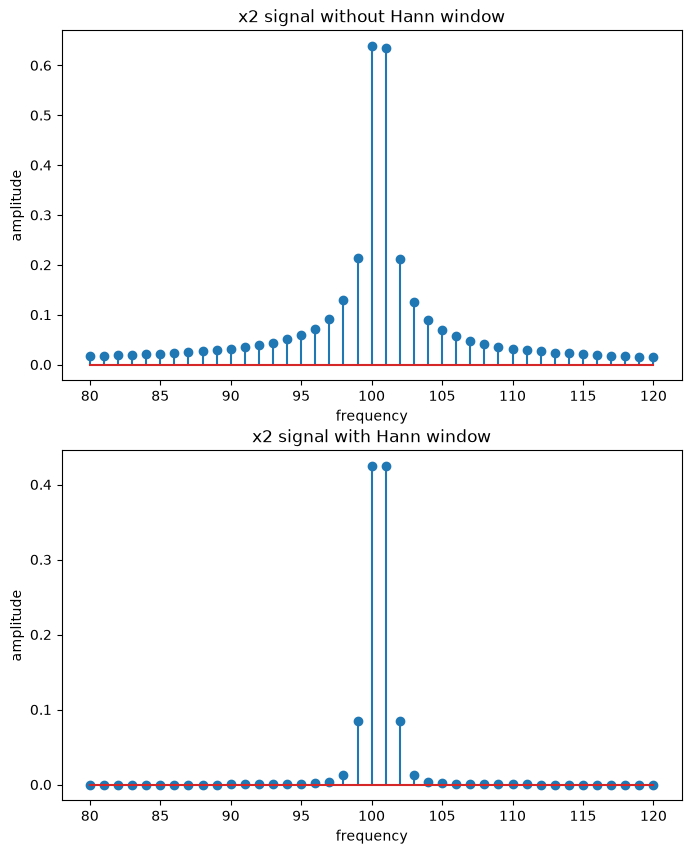

In [4]:
# Plot stem between 80-120 Hz with Hann window and without Hann window

# subplots(2,1) is create graph in the same image but separate into 2 rows.
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(8, 10)) 

ax1.set(xlabel="frequency", ylabel="amplitude", title="x2 signal without Hann window")


# Note: remind myself -> "Objective of plot this graph is using frequency and amplitude (magnitude) to plot frequency spectrum."
# You have to using magnitude in y-axis not FFT of the signal. 

ax1.stem(freqs[80:121], mag2[80:121])

ax2.set(xlabel="frequency", ylabel="amplitude", title="x2 signal with Hann window")
ax2.stem(freqs[80:121], hann_mag2[80:121])

**ST2 (โค้ด) หั่นสัญญาณเป็นเฟรม แล้วย้ายฟังก์ชันเข้า `dsp/`**
  - **ทำ:**
    - สร้างไฟล์ `dsp/spectral.py` → เขียน `frame_signal(x, frame_len, hop)` พร้อม docstring → คืน array 2 มิติ shape `(n_frames, frame_len)`
    - เฟรมที่ m คือ `x[m*hop : m*hop + frame_len]`
    - ทดสอบกับตัวเลขที่รู้คำตอบก่อน: `frame_signal(np.arange(10), 4, 2)` → `[[0,1,2,3], [2,3,4,5], [4,5,6,7], [6,7,8,9]]` (เช็คด้วย `np.allclose`)
    - ลอง `frame_signal(np.arange(10), 4, 3)` → print ผลและ `.shape`
    - `sr = 8000` สร้างโน้ต 3 ตัว ตัวละ 0.5 วินาที แอมพลิจูด 0.5 ที่ 440, 660, 880 Hz → ต่อกันเป็น `x` → `len(x)` ได้ 12000
    - `frames = frame_signal(x, 512, 256)` → print `frames.shape`
    - เช็ค `np.allclose(frames[3], x[768:1280])`
  - **เครื่องมือใหม่:**
    - ต่อ array: `np.concatenate([np.array([1, 2]), np.array([3])])` → `[1, 2, 3]`
    - `np.array([[1, 2], [3, 4], [5, 6]]).shape` → `(3, 2)` คือ 3 แถว 2 คอลัมน์
  - **ใบ้:** จำนวนเฟรม = `1 + (len(x) - frame_len) // hop` (`//` คือหารปัดเศษทิ้ง)
  - **ตอบ:**
    1. `frame_signal(np.arange(10), 4, 3)` ได้กี่เฟรม
    > `frame_signal(np.arange(10), 4, 3)` จะได้ 3 เฟรม
    2. `frames.shape` ของสัญญาณ 3 โน้ตเป็นเท่าไร
    >  `frames.shape` ของสัญญาณ 3 โน้ตเป็น (45, 512) หมายความว่าเป็น array ที่มีทั้งหมด 45 array ย่อยและแต่ละ array ย่อยมีข้อมูลทั้งหมด 512 ตัว
    3. เฟรมที่ 3 เริ่มที่ sample ที่เท่าไร
    > เฟรมที่ 3 เริ่มที่ sample = $Hopsize \times m = 256 \times 3 = 768$
  - **เสร็จเมื่อ:** import `frame_signal` จาก `dsp.spectral` ได้ / ทดสอบตัวเลขเล็กได้ True / shape ได้ `(45, 512)` / `np.allclose` ได้ True และตอบครบ 3 ข้อ

In [5]:
# Testing frame_signal function within notebooks
test = frame_signal(np.arange(10), 4, 3)
print(f"Testing frame_signal function with (np.arange(10), 4, 3) : {test}")
print(f"test shape : {test.shape}")


Testing frame_signal function with (np.arange(10), 4, 3) : [[0 1 2 3]
 [3 4 5 6]
 [6 7 8 9]]
test shape : (3, 4)


In [6]:
sr = 8000
t = make_time(0, 1.5, sr)   # create time for the whold signal
t_signal = make_time(0, 0.5, sr)
sine_440 = create_sin(0.5, 440, t_signal)
sine_660 = create_sin(0.5, 660, t_signal)
sine_880 = create_sin(0.5, 880, t_signal)

x = np.concatenate([sine_440, sine_660, sine_880])
print(f"Check number of sample that concatenate : {len(x)}")

Check number of sample that concatenate : 12000


In [7]:
frames = frame_signal(x, 512, 256)
print(f"Shape of signal x : {frames.shape}")
print(f"Check with np.allclose() at m = 4 or frame[3] : {np.allclose(frames[3], x[768:1280])}")

Shape of signal x : (45, 512)
Check with np.allclose() at m = 4 or frame[3] : True


**ST3 (โค้ด + หู) STFT และ spectrogram: FFT ทั้งก้อน vs ทีละเฟรม**
  - **ทำ:**
    - ฟัง `x` จาก ST2 ด้วย `Audio(x, rate=sr)`
    - สร้าง `x_rev` = 3 โน้ตเดิมแต่เรียงกลับ (880, 660, 440)
    - FFT ทั้งก้อน: `np.abs(np.fft.rfft(x))` กับของ `x_rev` → เช็ค `np.allclose` ของสองตัวนี้
    - STFT: `frames * np.hanning(512)` → `S = np.abs(np.fft.rfft(..., axis=1))` → print `S.shape`
    - `freqs = np.fft.rfftfreq(512, 1/sr)` → print `freqs[1] - freqs[0]`
    - print `freqs[np.argmax(S[m])]` ที่ m = 5, 20, 40
    - ทำ STFT ของ `x_rev` แบบเดียวกัน → พล็อต spectrogram ของ `x` กับ `x_rev` ด้วย `plt.subplots(1, 2)` (แกน x = เวลา s, แกน y = Hz)
  - **เครื่องมือใหม่:**
    - `np.fft.rfft(a, axis=1)` → FFT ทีละแถว และเก็บแค่ 0 ถึง sr/2 จึงได้ `frame_len // 2 + 1` คอลัมน์
    - `np.fft.rfftfreq(4, 1/8)` → `[0, 2, 4]` คือความถี่ (Hz) ของแต่ละคอลัมน์
    - `ax.imshow(S.T, origin='lower', aspect='auto', extent=[0, len(x)/sr, 0, sr/2])` → `.T` สลับแถวกับคอลัมน์ ให้เวลาอยู่แกน x
  - **ตอบ:**
    1. `np.allclose` ของ FFT ทั้งก้อน (`x` กับ `x_rev`) ได้ True หรือ False
    >  `np.allclose` ของ FFT ทั้งก้อน (`x` กับ `x_rev`) ได้ True เพราะว่า ทั้งสองสัญญาณมีองค์ประกอบของความถี่ที่เท่ากันเพียงแต่มีการกลับด้านซึ่งหมายความว่าที่เวลาเท่ากันจะมีองค์ประกอบของความถี่ที่ไม่เท่ากัน ซึ่งเป็นจุดอ่อนของ FFT
    2. ที่ m = 20 ความถี่ที่ดังสุดคือกี่ Hz
    > ที่ m = 20 ความถี่ที่ดังที่สุด คือ 656.25 Hz
    3. `freqs[1] - freqs[0]` ได้กี่ Hz
    > `freqs[1] - freqs[0]` หมายถึง frequency bins ที่ช่วงของความถี่ช่องสัญญาณมีความถี่เท่ากับ 15.625 Hz
  - **เสร็จเมื่อ:** `np.allclose` ได้ True / `S.shape` ได้ `(45, 257)` / m = 5, 20, 40 ได้ 437.5, 656.25, 875.0 / ระยะ bin 15.625 / มี spectrogram 2 รูปที่เห็นเส้นเป็นขั้นบันไดคนละทิศ และตอบครบ 3 ข้อ

In [8]:
Audio(x, rate=sr)

In [9]:
x_rev = np.concatenate([sine_880, sine_660, sine_440])

x_fft = np.abs(np.fft.rfft(x))
x_rev_fft = np.abs(np.fft.rfft(x_rev))
print(f"Check x_fft and x_rev_fft with np.allclose() : {np.allclose(x_fft, x_rev_fft)}")

Check x_fft and x_rev_fft with np.allclose() : True


In [10]:
frame_window = frames * np.hanning(512)
S = np.abs(np.fft.rfft(frame_window, axis=1))

# The results is (45, 257) means after did STFT.
# The whole 45 frames have FFT already each frames contain 257 values.
print(f"STFT shape of frame : {S.shape}\n")

freqs = np.fft.rfftfreq(512, 1/sr)
print(freqs[1]-freqs[0])

m_test = [5, 20, 40]
results = []
for m in m_test:
    results.append(freqs[np.argmax(S[m])])

outputs = zip(m_test, results)

for m_index, frequency in outputs:
    print(f"m = {m_index} : {frequency}")

STFT shape of frame : (45, 257)

15.625
m = 5 : 437.5
m = 20 : 656.25
m = 40 : 875.0


In [11]:
# STFT with x_rev

# Framing and windowing
frames_x_rev = frame_signal(x_rev, 512, 256)
frames_window_x_rev = frames_x_rev * np.hanning(512)

# STFT
S_x_rev = np.abs(np.fft.rfft(frames_window_x_rev, axis=1))
print(f"STFT shape of frame : {S_x_rev.shape}")

STFT shape of frame : (45, 257)


[Text(0.5, 0, 'time (s)'),
 Text(0, 0.5, 'frequency (Hz)'),
 Text(0.5, 1.0, 'Spectrogram of x_rev signal')]

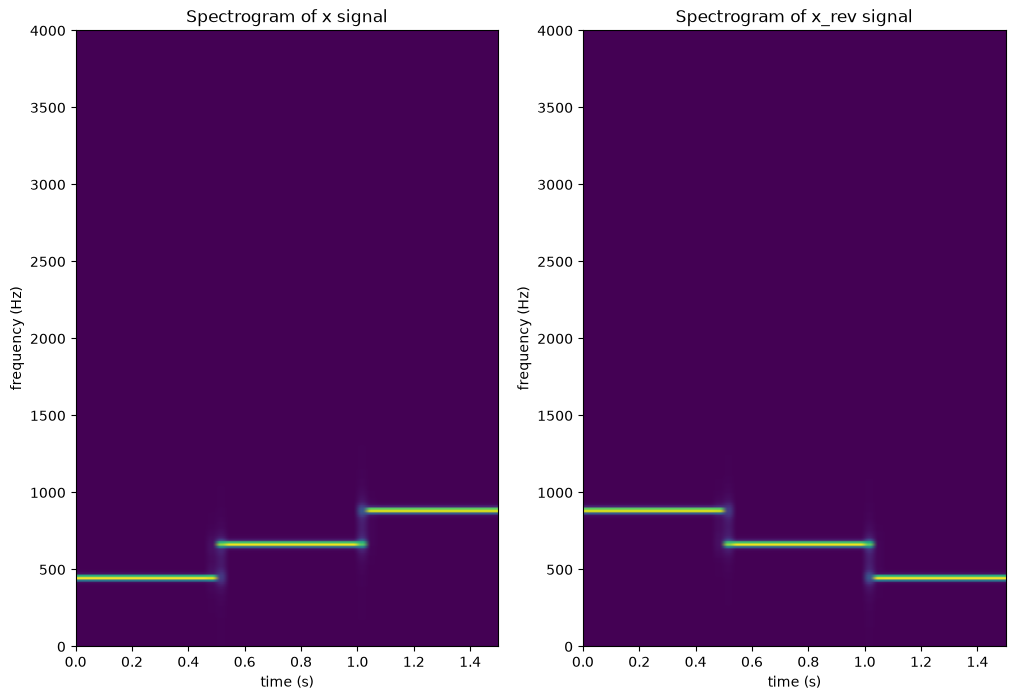

In [12]:
# Plot Spectrogram 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,8))

ax1.imshow(S.T, origin='lower', aspect='auto', extent=[0, len(x)/sr, 0, sr/2])
ax1.set(xlabel="time (s)", ylabel="frequency (Hz)", title="Spectrogram of x signal")

ax2.imshow(S_x_rev.T, origin='lower', aspect='auto', extent=[0, len(x)/sr, 0, sr/2])
ax2.set(xlabel="time (s)", ylabel="frequency (Hz)", title="Spectrogram of x_rev signal")


**ST4 (โค้ด) เขียน `stft()` เข้า `dsp/spectral.py` แล้วเทียบกับ `librosa.stft`**
  - **ทำ:**
    - ทำต่อใน `notebooks/06_STFT.ipynb`
    - เพิ่ม `stft(x, frame_len, hop)` พร้อม docstring ใน `dsp/spectral.py` → ข้างในเรียก `frame_signal` → คูณ `np.hanning(frame_len)` → `np.abs(np.fft.rfft(..., axis=1))`
    - ทดสอบกับ `x` 3 โน้ตจาก ST2: `S = stft(x, 512, 256)` → print `S.shape`
    - `L = librosa.stft(x, n_fft=512, hop_length=256, window=np.hanning(512), center=False)` → print `L.shape`
    - เช็ค `np.allclose(S, np.abs(L).T)`
    - เรียก `librosa.stft(x, n_fft=512, hop_length=256)` แบบค่า default → print `.shape`
  - **เครื่องมือใหม่:**
    - `librosa.stft` คืนค่าเป็นจำนวนเชิงซ้อน shape `(ความถี่, เฟรม)` สลับกับของเรา จึงต้อง `np.abs(...)` แล้ว `.T`
    - `center=True` (ค่า default) จะเติม 0 หน้าและหลังสัญญาณข้างละ `n_fft // 2` ก่อนหั่นเฟรม
  - **ตอบ:**
    1. `L.shape` ได้เท่าไร
    > L.shape แบบที่ยังไม่มีการ Transpose จะมีค่าเท่ากับ (257, 45) แต่ถ้ามีการ Transpose แล้วจะมีค่าเท่ากับ (45, 257) โดยตัวเลข 45 จะหมายถึงสัญญาณของเรามีการทำ framing ทั้งหมด 45 frames และตัวเลข 257 หมายถึง แต่ละ frames จะมี frequency bins ทั้งหมดเท่ากับ 257 ช่องสัญญาณ
    2. `np.allclose(S, np.abs(L).T)` ได้ True หรือ False
    > ผลลัพธ์ที่ได้จากการใช้คำสั่ง `np.allclose(S, np.abs(L).T)` มีค่าเท่ากับ True
    3. แบบ default ได้กี่เฟรม
    > การใช้งานฟังก์ชัน `librosa.stft()` แบบ default จะให้ทั้งหมด 47 frames โดยเติม 0 หน้าและหลังสัญญาณก่อนทำการ framing
  - **เสร็จเมื่อ:** import `stft` จาก `dsp.spectral` ได้ / `S.shape` ได้ `(45, 257)` / `L.shape` ได้ `(257, 45)` / `np.allclose` ได้ True / แบบ default ได้ `(257, 47)` และตอบครบ 3 ข้อ

In [13]:
# Test stft(x, frame_len, hop) from dsp/spectral.py 
S_fx = stft(x, 512, 256)
print(f"Check shape of STFT from my function : {S_fx.shape}")

L = librosa.stft(x, n_fft=512, hop_length=256, window=np.hanning(512), center=False)
print(f"Check shape of STFT from Librosa function : {L.T.shape}") # Columns of stft in librosa are each frames

print(f"Check with np.allclose() between S_fx and L : {np.allclose(S_fx, np.abs(L.T))}")

# Test with call librosa.stft() default
L_default = librosa.stft(x, n_fft=512, hop_length=256)
print(f"Check shape of STFT from default Librosa function : {L_default.shape}")

Check shape of STFT from my function : (45, 257)
Check shape of STFT from Librosa function : (45, 257)
Check with np.allclose() between S_fx and L : True
Check shape of STFT from default Librosa function : (257, 47)


**ST5 (โค้ด + สังเกต) Spectrogram แบบ dB: เห็นเสียงเบาที่ซ่อนอยู่**
  - **ทำ:**
    - `sr = 8000` สร้าง `t` 1 วินาที → `x = create_sin(1, 500, t) + create_sin(0.01, 1500, t)`
    - `S = stft(x, 512, 256)` → print `S.shape`
    - `freqs = np.fft.rfftfreq(512, 1/sr)` → หา index ของ 500 Hz กับ 1500 Hz
    - print `S[10]` ที่ 500 Hz, ที่ 1500 Hz และผลหารของสองค่านี้
    - `S_db = 20 * np.log10(S + 1e-10)` → print `S_db[10]` ที่ 500 Hz, ที่ 1500 Hz และผลต่างของสองค่านี้
    - พล็อต spectrogram ของ `S` กับ `S_db` ด้วย `plt.subplots(1, 2)` (แบบ dB ใส่ `vmin=S_db.max() - 80`)
  - **เครื่องมือใหม่:**
    - dB ของขนาด: `20 * np.log10(10)` → 20, `20 * np.log10(0.1)` → -20 (ขนาดต่างกัน 10 เท่า = ต่างกัน 20 dB)
    - `ax.imshow(..., vmin=-5)` → ค่าที่ต่ำกว่า -5 จะเป็นสีเดียวกันหมด กราฟจะไม่ถูกค่าติดลบมาก ๆ ดึงสีไปใช้หมด
  - **ใบ้:** บวก `1e-10` ไว้กัน `log10(0)` ซึ่งได้ `-inf`
  - **ตอบ:**
    1. ผลหาร `S` ที่ 500 Hz ต่อ 1500 Hz ได้เท่าไร
    > ผลหารของ S ที่ 500 Hz ต่อ 1500 Hz ได้เท่ากับประมาณ 100
    2. ผลต่าง dB ของสองความถี่นี้ได้กี่ dB
    > ผลต่าง dB ของสองความถี่นี้ได้ประมาณ 40 dB หรือน่าจะประมาณ 100 เท่า (เพราะว่า 20 dB เท่ากับ 10 เท่า เลยคิดว่า 40 dB น่าจะ 100 เท่า)
    3. เส้น 1500 Hz มองเห็นในรูปไหน: แบบเส้นตรง (linear), แบบ dB หรือทั้งสองรูป
    > เส้น 1500 Hz มองเห็นได้แค่ในรูปที่เป็น dB เท่านั้น
  - **เสร็จเมื่อ:** `S.shape` ได้ `(30, 257)` / index ได้ 32 กับ 96 / ผลหาร ≈100 / `S_db` ที่ 500 Hz ≈42.1 และผลต่าง ≈40.0 dB / มีกราฟ 2 รูป และตอบครบ 3 ข้อ

In [14]:
sr = 8000
t = make_time(0,1,sr)
x = create_sin(1, 500, t) + create_sin(0.01, 1500, t)
S = stft(x, 512, 256)

print(f"Check shape of S : {S.shape}")
freqs = np.fft.rfftfreq(512, 1/sr)
k_500 = np.argmin(np.abs(freqs - 500))
k_1500 = np.argmin(np.abs(freqs - 1500))

print(f"Check freqs at index 500 and 1500 : {k_500} and {k_1500}")  
print(f"Check S[10] at 500 Hz: {round(S[10, k_500],2)}")
print(f"Check S[10] at 1500 Hz: {round(S[10, k_1500],2)}")
print(f"Check S[10] at 500 / 1500 : {round(S[10, k_500]/S[10, k_1500],2)}")

S_db = 20 * np.log10(S + 1e-10)
S_db_500 = S_db[10, k_500]
S_db_1500 = S_db[10, k_1500]
print(f"dB at 500 of S[10, 500] : {round(S_db_500,2)} dB")
print(f"dB at 1500 of S[10, 1500] : {round(S_db_1500,2)} dB")
print(f"dB diff between 1500 and 500 : {round(np.abs(S_db_500 - S_db_1500),2)}")


Check shape of S : (30, 257)
Check freqs at index 500 and 1500 : 32 and 96
Check S[10] at 500 Hz: 127.75
Check S[10] at 1500 Hz: 1.28
Check S[10] at 500 / 1500 : 100.0
dB at 500 of S[10, 500] : 42.13 dB
dB at 1500 of S[10, 1500] : 2.13 dB
dB diff between 1500 and 500 : 40.0


[Text(0.5, 0, 'time (s)'),
 Text(0, 0.5, 'frequency (Hz)'),
 Text(0.5, 1.0, 'Spectrogram of STFT (dB) of x signal')]

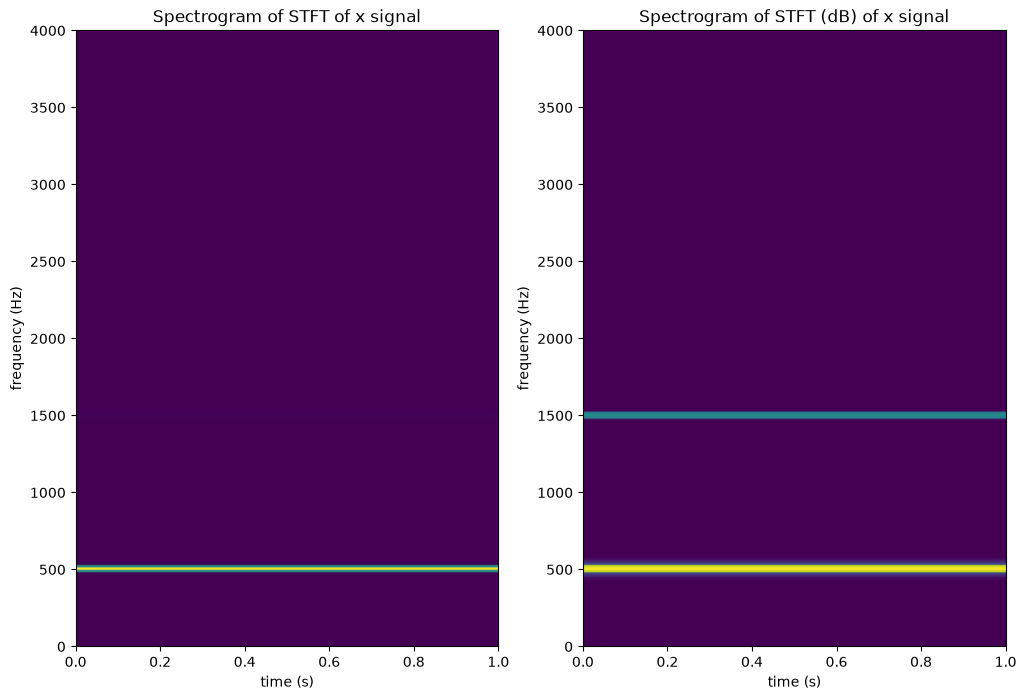

In [15]:
# Plot Spectrogram 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,8))

ax1.imshow(S.T, origin='lower', aspect='auto', extent=[0, len(x)/sr, 0, sr/2])
ax1.set(xlabel="time (s)", ylabel="frequency (Hz)", title="Spectrogram of STFT of x signal")

ax2.imshow(S_db.T, origin='lower', aspect='auto', extent=[0, len(x)/sr, 0, sr/2], vmin=S_db.max()-80)
ax2.set(xlabel="time (s)", ylabel="frequency (Hz)", title="Spectrogram of STFT (dB) of x signal")

**ST6 (โค้ด + สังเกต) Trade-off: เฟรมสั้นเห็นเวลาชัด เฟรมยาวเห็นความถี่ชัด**
  - **ทำ:**
    - `sr = 8000` สร้าง `t` 1 วินาที → `x = create_sin(0.5, 440, t) + create_sin(0.5, 470, t)`
    - ใส่เสียงคลิก: `x[2000] += 1` → คือเวลา 0.25 วินาที
    - ใช้ `for frame_len in [128, 2048]:` โดย `hop = frame_len // 4` (ห้าม copy โค้ดสองชุด)
    - ในลูป: `S = stft(x, frame_len, hop)` → print ระยะ bin (Hz) และความยาวเฟรม (ms)
    - ในลูป: เฟรมกลาง `m = len(S) // 2` → พล็อต stem ของ `S[m]` ช่วง 300–600 Hz
    - ในลูป: พล็อต spectrogram แบบ dB (`vmin=S_db.max() - 80`)
  - **เครื่องมือใหม่:**
    - วางกราฟในลูป: `fig, axes = plt.subplots(2, 2)` แล้วใช้ `for i, frame_len in enumerate([128, 2048]):` → วาดลง `axes[i, 0]` กับ `axes[i, 1]`
    - `enumerate(['a', 'b'])` → ได้ `(0, 'a')`, `(1, 'b')`
  - **ตอบ:**
    1. `frame_len = 2048` มีระยะ bin กี่ Hz
    > ที่ frame_len = 2048 มีระยะ bin เท่ากับประมาณ 3.91 Hz
    2. `frame_len` ไหนที่เห็นยอด 440 กับ 470 Hz แยกเป็น 2 ยอด
    > ที่ frame_len = 2048 ที่จะเห็นยอด 440 กับ 470 Hz แยกเป็น 2 ยอด
    3. `frame_len` ไหนที่แถบแนวตั้งของเสียงคลิกใน spectrogram แคบกว่า
    > ที่ frame_len = 128 แถบแนวตั้งของเสียงคลิปใน Spectrogram จะแคบกว่า เกิดจาก trade-off ของการทำ time-frequency analysis หมายความว่า ยิ่ง frame_len มากขึ้น (ความละเอียดของเวลาน้อยลง) ความละเอียดของความถี่เพิ่มขึ้น ในขณะที่ยิ่ง frame_len น้อยลง (ความละเอียดของเวลามากขึ้น) ความละเอียดของความถี่จะลดลง
  - **เสร็จเมื่อ:** 128: ระยะ bin 62.5 Hz, เฟรมยาว 16 ms, เห็นยอดเดียวที่ ≈437.5 Hz / 2048: ระยะ bin ≈3.91 Hz, เฟรมยาว 256 ms, เห็น 2 ยอดที่ ≈441 กับ ≈469 Hz / มีกราฟ 4 รูปจากลูปเดียว และตอบครบ 3 ข้อ

at frame_len = 128
frequency bins width : 62.5 Hz and frame length : 16.0 ms
at frame_len = 2048
frequency bins width : 3.91 Hz and frame length : 256.0 ms


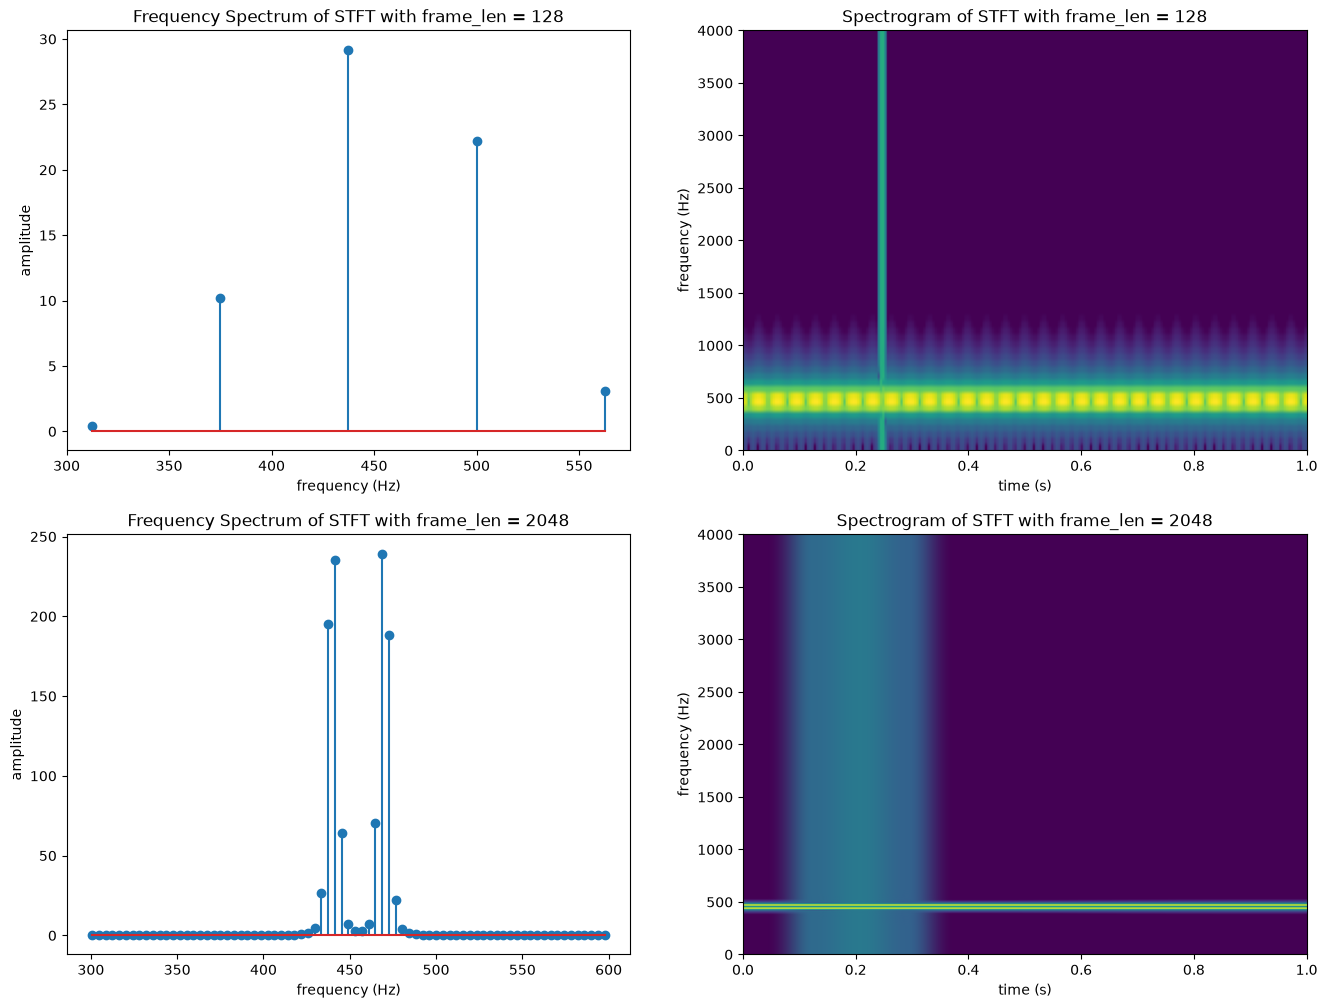

In [16]:
x = create_sin(0.5, 440, t) + create_sin(0.5, 470, t)
x[2000] += 1
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for i, frame_len in enumerate([128, 2048]):
    hop = frame_len // 4
    S = stft(x, frame_len, hop)
    S_db = 20 * np.log10(S+1e-10)
    freqs = np.fft.rfftfreq(frame_len, 1/sr)
    bins = freqs[1]-freqs[0]
    frame_length = 1/bins

    # Plot between 300 Hz - 600 Hz 
    masks = (freqs >= 300) & (freqs <= 600)

    print(f"at frame_len = {frame_len}")
    print(f"frequency bins width : {round(bins, 2)} Hz and frame length : {frame_length*1000} ms")
    m = len(S)//2
    axes[i, 0].set(xlabel="frequency (Hz)", ylabel="amplitude", title=f'Frequency Spectrum of STFT with frame_len = {frame_len}')
    axes[i, 0].stem(freqs[masks], S[m][masks])
    axes[i, 1].set(xlabel="time (s)", ylabel="frequency (Hz)", title=f'Spectrogram of STFT with frame_len = {frame_len}')
    axes[i, 1].imshow(S_db.T, origin="lower", aspect="auto", extent=[0, len(x)/sr, 0, sr/2], vmin=S_db.max()-80)